# JS-SoC: An RV32I System-on-Chip with Hardware Bootloader and APB Peripherals, from RTL to GDSII

**IEEE SSCS Code-a-Chip submission notebook**

**Team:** S Steven Joshua · Swatish Subramanian<br>
**Institution:** Vellore Institute of Technology, Chennai

**JS-SoC** is a SystemVerilog RV32I system-on-chip. A single-cycle RISC-V core is fed by a **hardware bootloader** that loads programs over an 8-bit interface, and it reaches **UART, PWM and Timer** peripherals through a bridge → FIFO → **APB** interconnect.

This notebook takes the design through the complete flow:

| Stage | Tooling | Outcome |
|---|---|---|
| RTL simulation | Icarus Verilog (open source) | 22-instruction program loaded and executed, `SIMULATION PASS` |
| RTL cross-verification | AMD Vivado 2024.1 | Bootloader, UART, Timer, PWM and integrated-SoC waveforms; lint clean |
| Open-source RTL → GDSII | Yosys + OpenROAD (ORFS), SkyWater **Sky130HD** | GDS at 35 MHz, no setup/hold violations, **0 DRC** |

### Contents

1. Design at a glance
2. System architecture
3. RTL organization
4. Hardware bootloader and demonstration program
5. RTL simulation with Icarus Verilog
6. Cross-verification in Vivado
7. Open-source RTL-to-GDSII on Sky130HD (OpenROAD)
8. Results summary
9. Reproducibility
10. Conclusion, license and references

> **How to run:** Sections 1–6 read files from this submission, so run them from the `notebook/` folder. Section 7 builds OpenROAD from source and runs the full physical-design flow. It was executed on **Google Colab**, and its outputs are kept so the results can be reviewed without re-running several hours of tool builds and routing.

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display

# Locate the submission root (this notebook lives in <root>/notebook/)
ROOT = Path.cwd().parent if (Path.cwd().parent / "rtl").is_dir() else Path.cwd()
assert (ROOT / "rtl").is_dir(), "Run this notebook from the notebook/ folder of the submission."

def show(rel_path, caption, width=820):
    # Display a figure from the submission with a caption
    display(Image(filename=str(ROOT / rel_path), width=width))
    display(Markdown(f"*{caption}*"))

print("Submission root :", ROOT.name)
print("RTL modules     :", len(list((ROOT / "rtl").glob("*.sv"))))
print("Testbench       :", ", ".join(p.name for p in (ROOT / "tb").glob("*.sv")))

Submission root : JS-SoC-Code-a-Chip-final
RTL modules     : 36
Testbench       : top_tb.sv


## 1. Design at a glance

**8-bit boot stream → Hardware Bootloader → Instruction Memory → RV32I core → Bridge → FIFO → APB master → UART / PWM / Timer**

- Single-cycle RV32I core with datapath, controller, ALU, register file and immediate extender
- Hardware bootloader that assembles four received bytes into each 32-bit instruction and holds the CPU until loading completes
- Separate instruction and data memories
- Address-decoding bridge that separates ordinary data-memory accesses from memory-mapped I/O
- FIFO-buffered APB master driving three APB slaves (UART, PWM, Timer)
- Self-checking system testbench with `$fatal` assertions and VCD output

| Region | Base address |
|---|---|
| Data memory | `0x0000_0000` |
| UART | `0x4000_0000` |
| PWM | `0x4000_0008` |
| Timer | `0x4000_000C` |

## 2. System architecture

The first figure shows the peripheral path: the core's store traffic enters the bridge control logic, is buffered in a FIFO, and is issued by the APB master to the selected slave. The second figure shows the full SoC, including how the bootloader takes over the instruction-memory address and write ports (through the PC/bootloader mux) while the core is stalled.

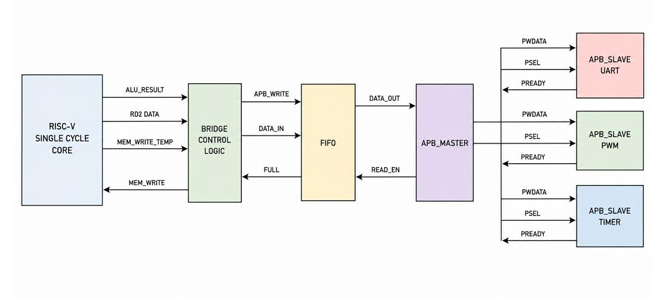

*Figure 1 – Core-to-peripheral path: bridge → FIFO → APB master → UART / PWM / Timer slaves*

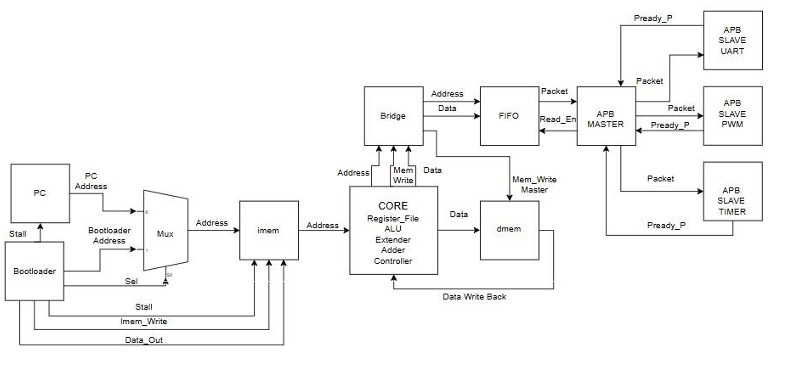

*Figure 2 – Complete JS-SoC architecture, including bootloader control of instruction memory*

In [2]:
show("docs/soc_block_diagram.png", "Figure 1 – Core-to-peripheral path: bridge → FIFO → APB master → UART / PWM / Timer slaves")
show("docs/soc_architecture.png", "Figure 2 – Complete JS-SoC architecture, including bootloader control of instruction memory")

## 3. RTL organization

The `rtl/` directory contains the complete working `SoC_V3` design. The cell below groups the modules by function and counts their source lines.

In [3]:
groups = {
    "CPU core":      ["core", "datapath", "controller", "main_decoder", "alu_decoder", "alu",
                      "register_file", "extender", "adder", "mux_2", "mux_3", "d_ff"],
    "Memories":      ["imem", "dmem"],
    "Bootloader":    ["bootloader"],
    "Interconnect":  ["bridge", "fifo", "fifo_master", "master", "apb_master", "control_logic",
                      "decoder_logic", "serializer", "deserializer"],
    "Peripherals":   ["uart_soc", "uart_tx", "uart_rx", "baud_rate", "apb_slave_uart",
                      "pwm", "apb_slave_pwm", "timer", "apb_slave_timer", "normal", "square"],
    "Top level":     ["top"],
}

import textwrap

rtl = {p.stem: p for p in (ROOT / "rtl").glob("*.sv")}
listed = set()
total = 0
print(f"{'Group':<14}{'Modules':>8}{'Lines':>7}   Files")
print("-" * 84)
for group, names in groups.items():
    present = [n for n in names if n in rtl]
    listed.update(present)
    lines = sum(len(rtl[n].read_text(errors="replace").splitlines()) for n in present)
    total += lines
    files = textwrap.wrap(", ".join(present), 52)
    print(f"{group:<14}{len(present):>8}{lines:>7}   {files[0]}")
    for more in files[1:]:
        print(" " * 32 + more)
print("-" * 84)
print(f"{'Total':<14}{len(listed):>8}{total:>7}")

unlisted = sorted(set(rtl) - listed)
if unlisted:
    print("\nOther modules:", ", ".join(unlisted))

Group          Modules  Lines   Files
------------------------------------------------------------------------------------
CPU core            12    641   core, datapath, controller, main_decoder,
                                alu_decoder, alu, register_file, extender, adder,
                                mux_2, mux_3, d_ff
Memories             2    163   imem, dmem
Bootloader           1    152   bootloader
Interconnect         9    811   bridge, fifo, fifo_master, master, apb_master,
                                control_logic, decoder_logic, serializer,
                                deserializer
Peripherals         11    967   uart_soc, uart_tx, uart_rx, baud_rate,
                                apb_slave_uart, pwm, apb_slave_pwm, timer,
                                apb_slave_timer, normal, square
Top level            1     63   top
------------------------------------------------------------------------------------
Total               36   2797


## 4. Hardware bootloader and demonstration program

The external programming interface is **8 bits wide**. The bootloader:

1. raises `bootloader_ready` and waits for a write strobe,
2. collects four bytes (MSB first) and assembles one 32-bit instruction,
3. writes that instruction into instruction memory and advances the write address,
4. after the announced number of instructions, de-asserts `HOLD`/`SEL` so the core starts fetching from address 0.

```text
Byte 3 (MSB) ─┐
Byte 2       ─┼──► 32-bit instruction ──► IMEM[addr++]
Byte 1       ─┤
Byte 0 (LSB) ─┘
```

The demonstration program has **22 RV32I instructions**. It writes to the memory-mapped peripherals and then runs arithmetic and logic operations whose results are checked in the register file.

In [4]:
words = [w.strip() for w in (ROOT / "programs" / "bootloader_demo.hex").read_text().split() if w.strip()]
print(f"Instructions in demonstration program: {len(words)}\n")
half = (len(words) + 1) // 2
for i in range(half):
    left = f"IMEM[{i:02d}] = 0x{words[i].upper()}"
    right = f"IMEM[{i + half:02d}] = 0x{words[i + half].upper()}" if i + half < len(words) else ""
    print(f"{left:<28}{right}")

Instructions in demonstration program: 22

IMEM[00] = 0x40000537       IMEM[11] = 0x00B52023
IMEM[01] = 0x486925B7       IMEM[12] = 0x0E0005B7
IMEM[02] = 0x12158593       IMEM[13] = 0x00A58593
IMEM[03] = 0x00B52023       IMEM[14] = 0x00B52023
IMEM[04] = 0x00850513       IMEM[15] = 0x00F00093
IMEM[05] = 0x000A05B7       IMEM[16] = 0x01400113
IMEM[06] = 0x00358593       IMEM[17] = 0x002081B3
IMEM[07] = 0x00B52023       IMEM[18] = 0x40118233
IMEM[08] = 0x00450513       IMEM[19] = 0x004182B3
IMEM[09] = 0x0C0A05B7       IMEM[20] = 0xFF628313
IMEM[10] = 0x00658593       IMEM[21] = 0x00000063


## 5. RTL simulation with Icarus Verilog

The system testbench `tb/top_tb.sv`:

- drives clock, reset and the 8-bit bootloader interface,
- streams all 22 instructions byte by byte,
- checks the bootloader state, instruction count and instruction-memory contents,
- lets the CPU run, then checks the architectural register values,
- stops with `$fatal` on any mismatch and prints `SIMULATION PASS` otherwise.

The cell below compiles and runs it. It runs the same commands as `scripts/run_sim.sh`. On Colab or Ubuntu, install the simulator first with `!apt-get install -y iverilog`.

In [5]:
import shutil, subprocess

if shutil.which("iverilog") is None:
    print("Icarus Verilog not found. Install it (e.g. `apt-get install -y iverilog`) and re-run.")
else:
    (ROOT / "results" / "build").mkdir(parents=True, exist_ok=True)
    sources = sorted(p.relative_to(ROOT).as_posix() for p in (ROOT / "rtl").glob("*.sv"))
    compile_ = subprocess.run(
        ["iverilog", "-g2012", "-s", "cpu_tb", "-o", "results/build/simv", *sources, "tb/top_tb.sv"],
        cwd=ROOT, capture_output=True, text=True)
    print("Compile exit code:", compile_.returncode)
    sim = subprocess.run(["vvp", "results/build/simv"], cwd=ROOT, capture_output=True, text=True)
    sim_log = sim.stdout
    print(sim_log)

Compile exit code: 0
VCD info: dumpfile results/build/js_soc.vcd opened for output.

       BOOTLOADER COMPLETE
COUNT      = 22
INSTR_CNT  = 22
HOLD       = 0
SEL        = 0

IMEM CONTENT
IMEM[0]  = 40000537
IMEM[1]  = 486925b7
IMEM[2]  = 12158593
IMEM[3]  = 00b52023
IMEM[4]  = 00850513
IMEM[5]  = 000a05b7
IMEM[6]  = 00358593
IMEM[7]  = 00b52023
IMEM[8]  = 00450513
IMEM[9]  = 0c0a05b7
IMEM[10] = 00658593
IMEM[11] = 00b52023
IMEM[12] = 0e0005b7
IMEM[13] = 00a58593
IMEM[14] = 00b52023
IMEM[15] = 00f00093
IMEM[16] = 01400113
IMEM[17] = 002081b3
IMEM[18] = 40118233
IMEM[19] = 004182b3
IMEM[20] = ff628313
IMEM[21] = 00000063

CPU REGISTER FILE
x0  = 00000000
x1  = 0000000f
x2  = 00000014
x3  = 00000023
x4  = 00000014
x5  = 00000037
x6  = 0000002d
x7  = 00000000
SIMULATION PASS
tb/top_tb.sv:168: $finish called at 427000 (1ps)



The cell below parses the simulator output and compares the register file with the values the program should produce.

In [6]:
import re

expected = {"x0": 0x00, "x1": 0x0F, "x2": 0x14, "x3": 0x23,
            "x4": 0x14, "x5": 0x37, "x6": 0x2D, "x7": 0x00}
observed = {r: int(v, 16) for r, v in re.findall(r"^(x\d+)\s*=\s*([0-9a-fA-F]+)", sim_log, re.M)}

print(f"{'Reg':<5}{'Expected':>12}{'Observed':>12}   Status")
for reg, exp in expected.items():
    obs = observed.get(reg)
    status = "PASS" if obs == exp else "FAIL"
    obs_txt = f"0x{obs:08X}" if obs is not None else "missing"
    print(f"{reg:<5}{f'0x{exp:08X}':>12}{obs_txt:>12}   {status}")

count = re.search(r"INSTR_CNT\s*=\s*(\d+)", sim_log)
print("\nInstructions loaded by bootloader:", count.group(1) if count else "n/a")
print("Overall result:", "SIMULATION PASS" if "SIMULATION PASS" in sim_log else "FAIL")

Reg      Expected    Observed   Status
x0     0x00000000  0x00000000   PASS
x1     0x0000000F  0x0000000F   PASS
x2     0x00000014  0x00000014   PASS
x3     0x00000023  0x00000023   PASS
x4     0x00000014  0x00000014   PASS
x5     0x00000037  0x00000037   PASS
x6     0x0000002D  0x0000002D   PASS
x7     0x00000000  0x00000000   PASS

Instructions loaded by bootloader: 22
Overall result: SIMULATION PASS


The testbench also writes the waveform `results/build/js_soc.vcd`, which opens in GTKWave or any VCD viewer. The two captures below come from the same system testbench viewed in Vivado's waveform viewer. They show the bootloader programming instruction memory and the core executing the loaded program.

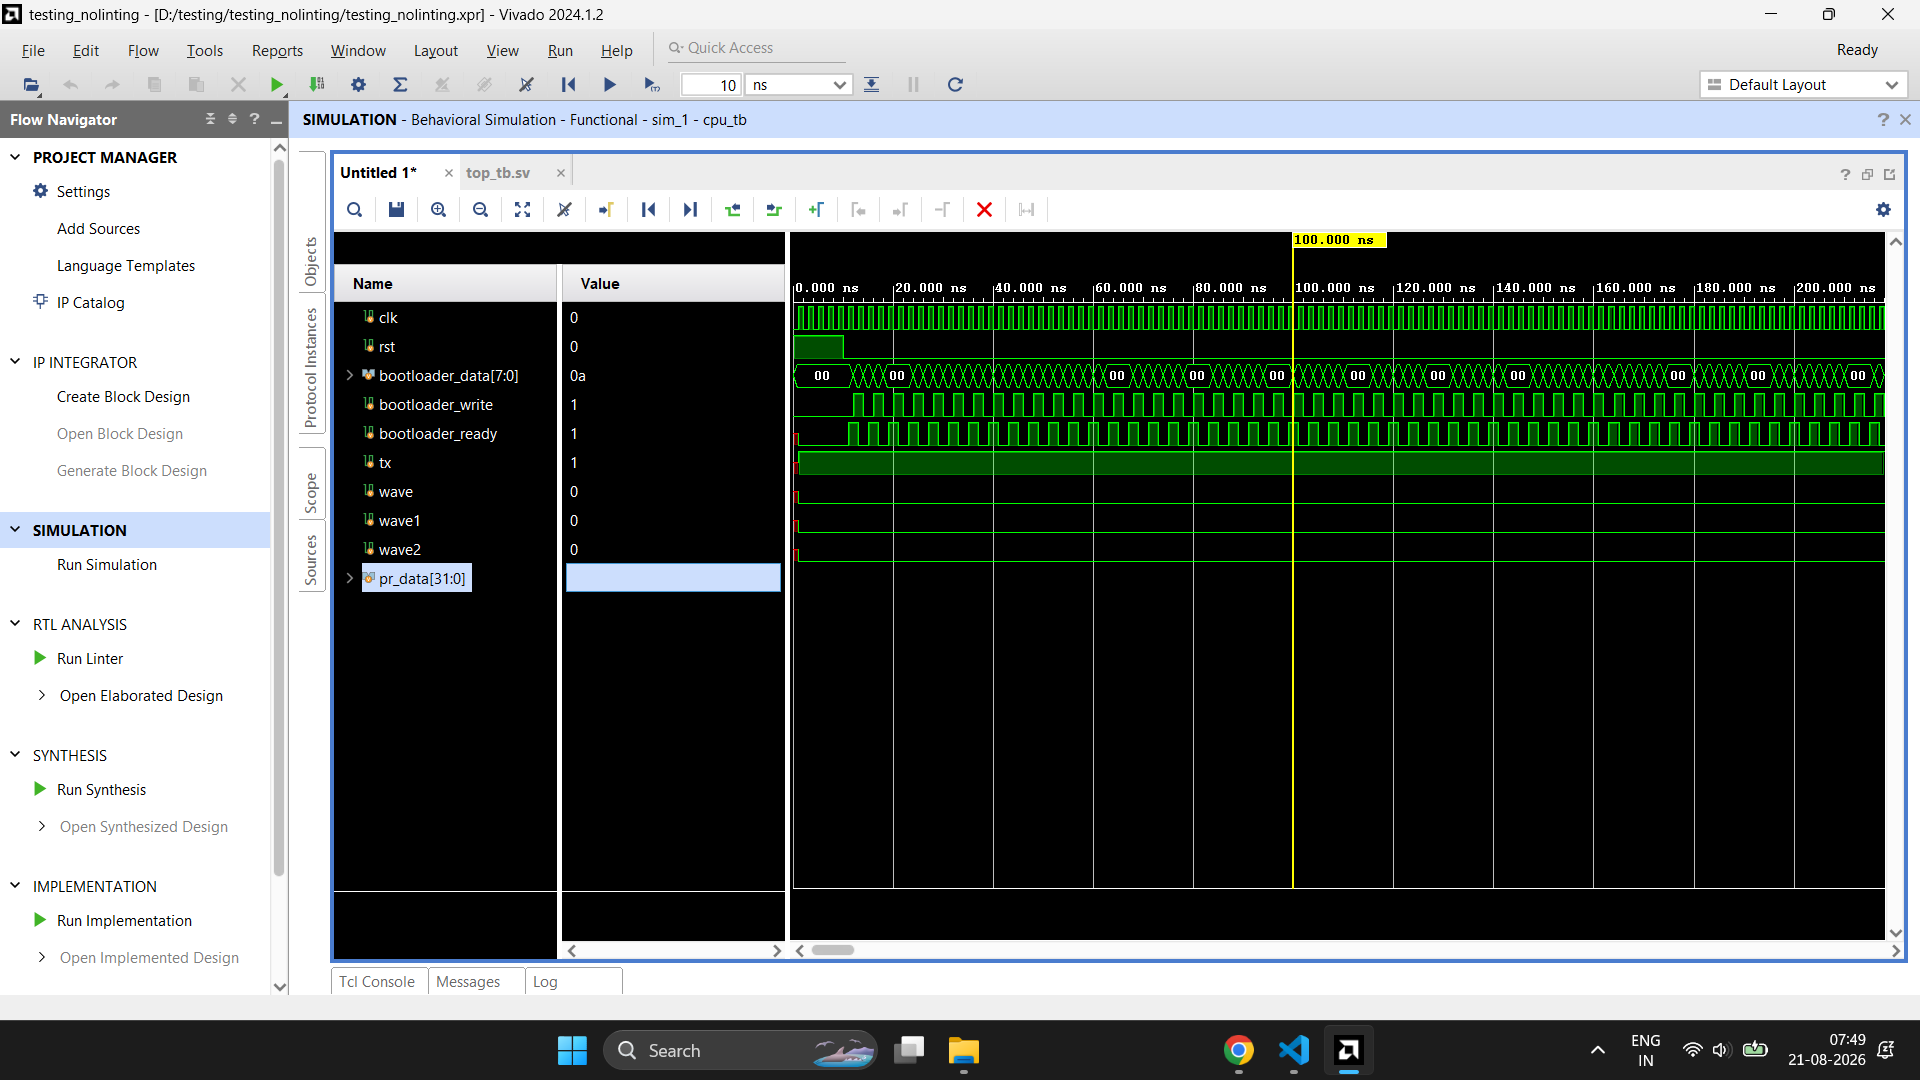

*Figure 3 – Bootloader receiving bytes and writing instructions into IMEM*

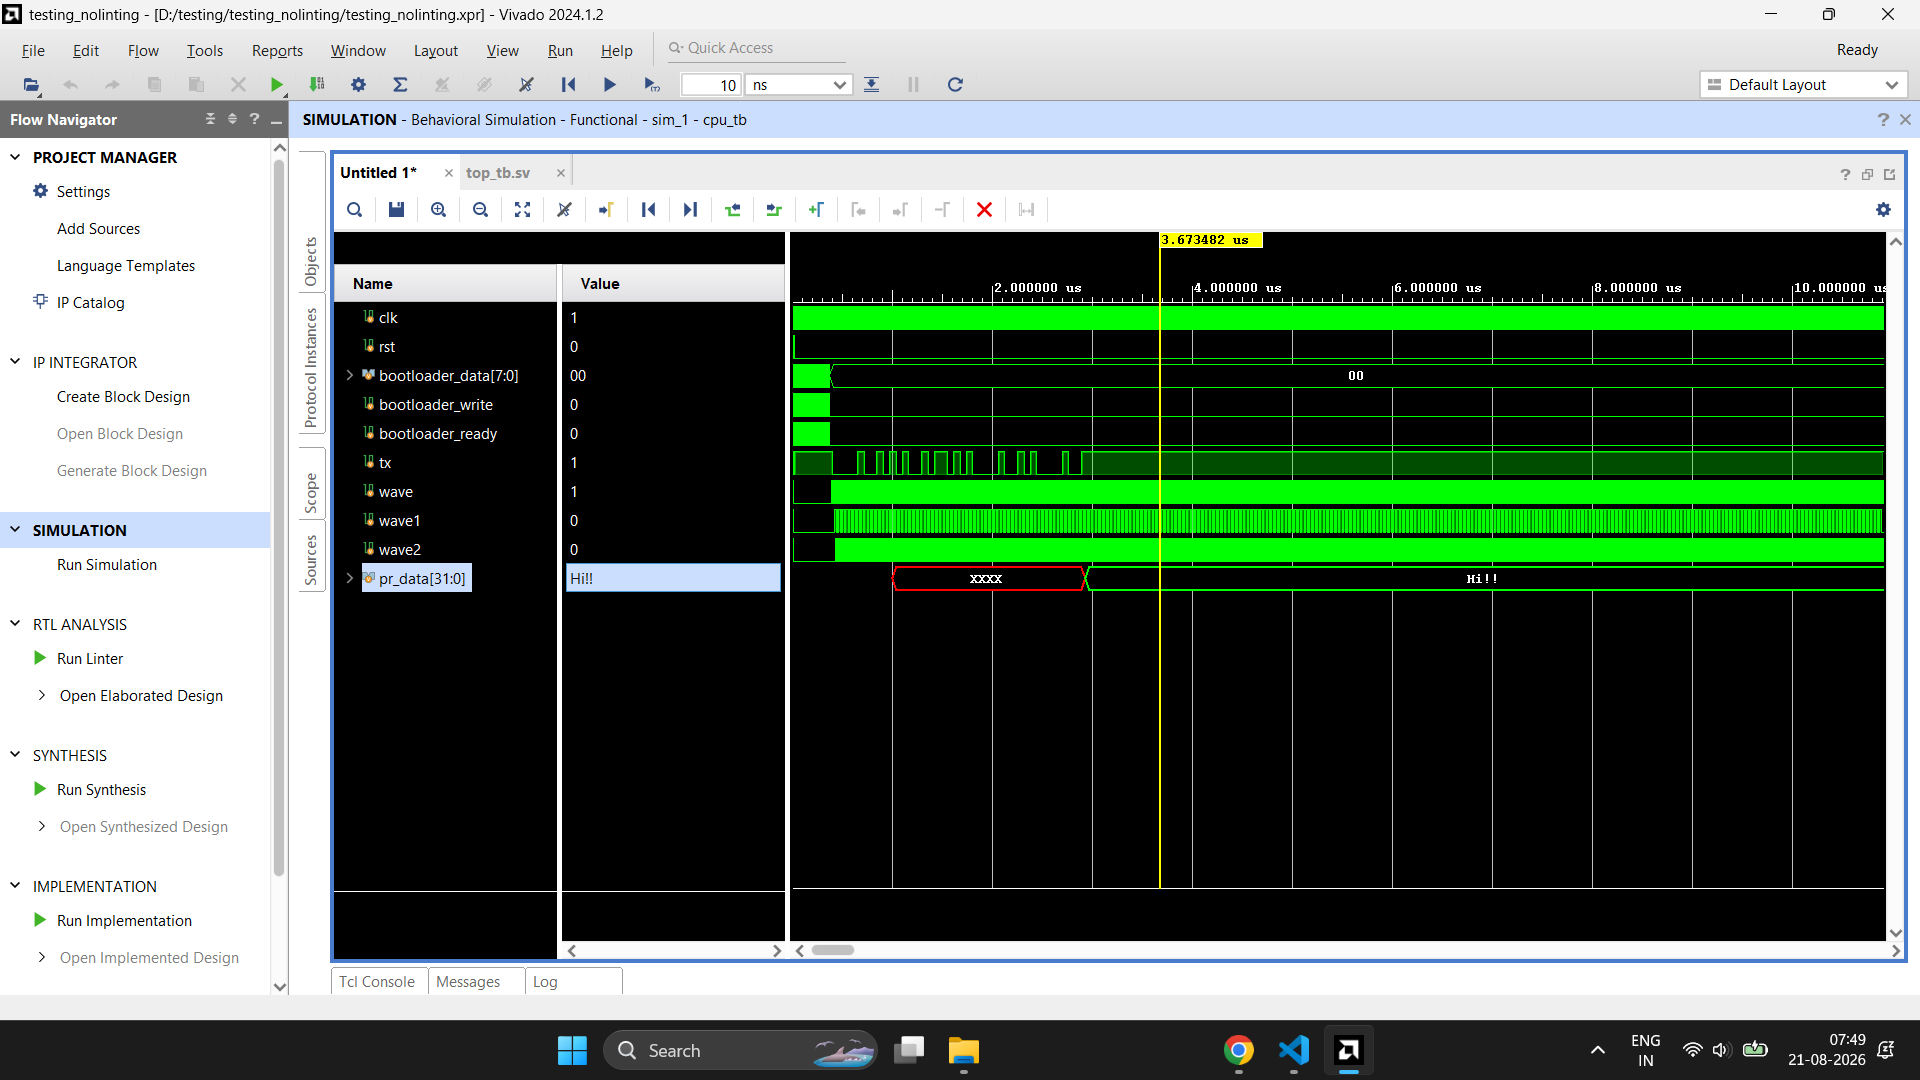

*Figure 4 – CPU released from HOLD and executing the loaded program*

In [7]:
show("results/bootloader_writing.png", "Figure 3 – Bootloader receiving bytes and writing instructions into IMEM")
show("results/execution.png", "Figure 4 – CPU released from HOLD and executing the loaded program")

## 6. Cross-verification in Vivado

The same RTL was also simulated in **AMD Vivado 2024.1** (behavioral simulation), with a separate testbench for each block and one for the integrated SoC. The Vivado RTL linter reported **0 warnings and 0 errors**.

| Testbench scope | What the waveform shows |
|---|---|
| Bootloader | Four-byte assembly, the assembled 32-bit word, IMEM write enable and write address |
| UART (via APB) | APB transfers to the UART slave and the transmitted characters |
| Timer (via APB) | Timer configuration over APB and the resulting output transitions |
| PWM (via APB) | Periodic PWM output for the programmed period and duty cycle |
| Integrated SoC | Boot, CPU release, register updates and peripheral outputs together |

Every peripheral access follows the APB **IDLE → SETUP → ACCESS** protocol: `PSEL` is asserted in SETUP, `PENABLE` in ACCESS, and the transfer completes on `PREADY`.

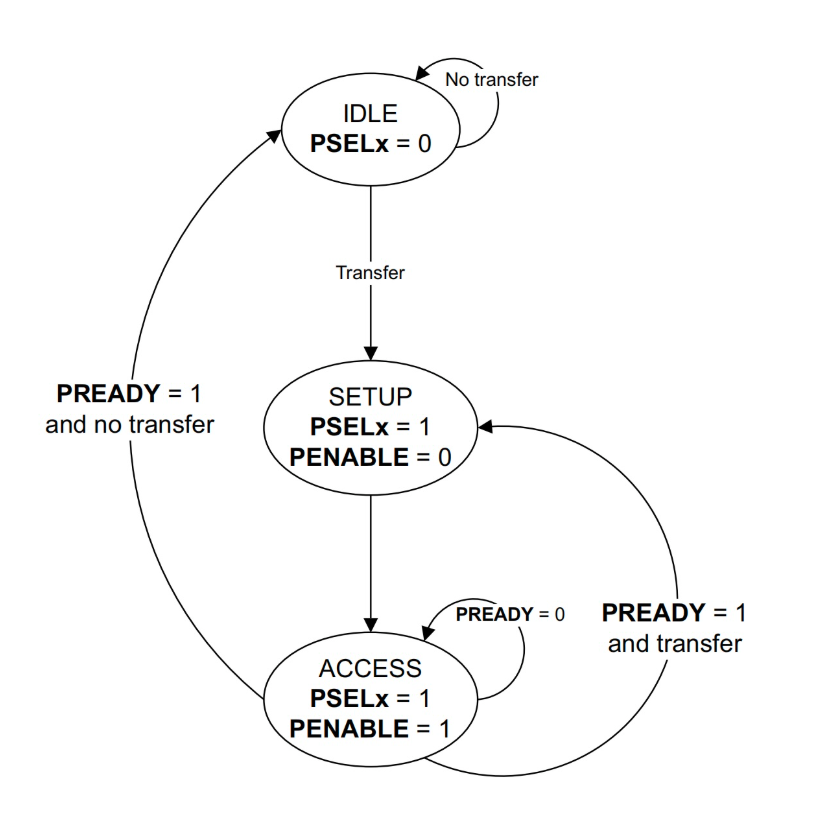

*Figure 5 – APB master state machine (IDLE → SETUP → ACCESS)*

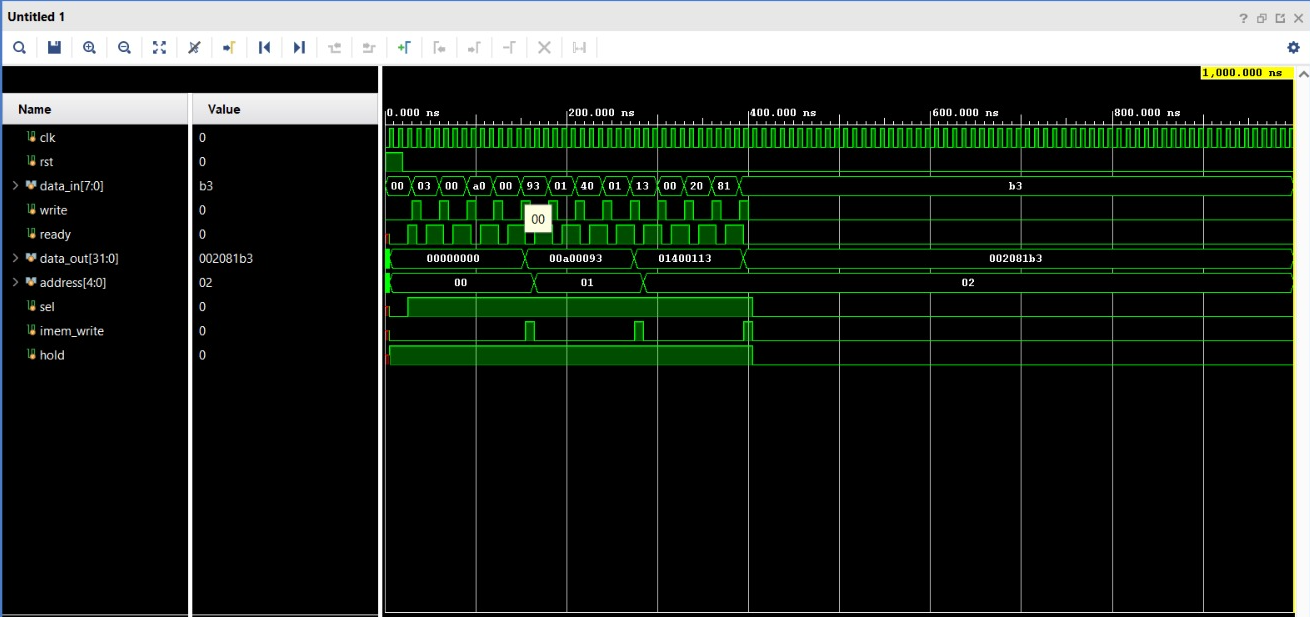

*Figure 6 – Vivado: bootloader assembling bytes into 32-bit words (0x00A00093, 0x01400113, 0x002081B3) and writing IMEM*

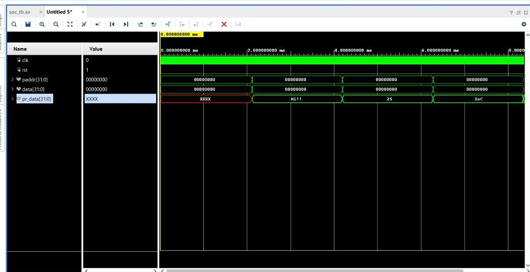

*Figure 7 – Vivado: UART accessed through the APB master*

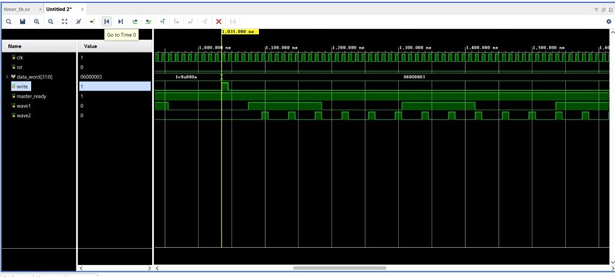

*Figure 8 – Vivado: timer peripheral output*

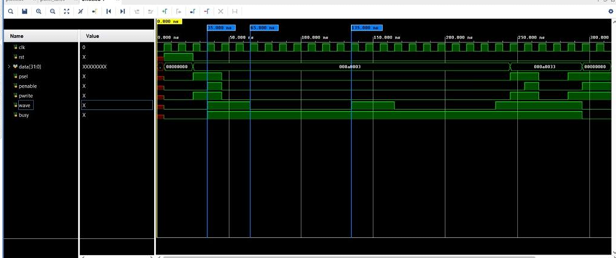

*Figure 9 – Vivado: PWM peripheral output*

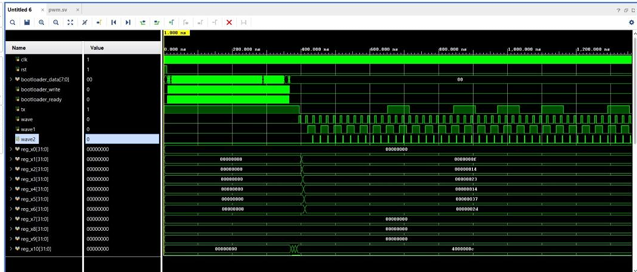

*Figure 10 – Vivado: integrated SoC (bootloading, register updates and peripheral outputs)*

In [8]:
show("results/vivado/apb_fsm.png", "Figure 5 – APB master state machine (IDLE → SETUP → ACCESS)", width=520)
show("results/vivado/bootloader_tb_waveform.png", "Figure 6 – Vivado: bootloader assembling bytes into 32-bit words (0x00A00093, 0x01400113, 0x002081B3) and writing IMEM")
show("results/vivado/uart_apb_waveform.png", "Figure 7 – Vivado: UART accessed through the APB master")
show("results/vivado/timer_waveform.png", "Figure 8 – Vivado: timer peripheral output")
show("results/vivado/pwm_waveform.png", "Figure 9 – Vivado: PWM peripheral output")
show("results/vivado/integrated_soc_waveform.png", "Figure 10 – Vivado: integrated SoC (bootloading, register updates and peripheral outputs)")

## 7. Open-source RTL-to-GDSII on Sky130HD (OpenROAD)

The unmodified `SoC_V3` RTL was implemented with **OpenROAD-flow-scripts (ORFS)**: Yosys synthesis, then OpenROAD floorplan, placement, CTS, global and detailed routing, then KLayout GDS merge and DRC. The target is the SkyWater **sky130_fd_sc_hd** library at **35 MHz**.

> These cells were executed on **Google Colab** (Ubuntu 24.04, 2 vCPUs). Building the tools from source takes a while, and the flow itself took about 1 h 46 min, mostly in detailed routing. Long tool logs are truncated, and each truncation is marked.

### 7.1 Get the RTL and OpenROAD-flow-scripts

In [9]:
%cd /content
!git clone https://github.com/S-Steven-Joshua/JS-SoC.git

/content
Cloning into 'JS-SoC'...
remote: Enumerating objects: 794, done.
remote: Counting objects: 100% (279/279), done.
remote: Compressing objects: 100% (260/260), done.
remote: Total 794 (delta 148), reused 4 (delta 4), pack-reused 515 (from 2)
Receiving objects: 100% (794/794), 1.53 MiB | 2.38 MiB/s, done.
Resolving deltas: 100% (352/352), done.


In [10]:
%cd /content
!git clone https://github.com/The-OpenROAD-Project/OpenROAD-flow-scripts.git

/content
Cloning into 'OpenROAD-flow-scripts'...
remote: Enumerating objects: 90488, done.
remote: Counting objects: 100% (1339/1339), done.
remote: Compressing objects: 100% (552/552), done.
remote: Total 90488 (delta 1071), reused 820 (delta 787), pack-reused 89149 (from 4)
Receiving objects: 100% (90488/90488), 895.18 MiB | 23.33 MiB/s, done.
Resolving deltas: 100% (68155/68155), done.
Updating files: 100% (2558/2558), done.


In [11]:
%cd /content/OpenROAD-flow-scripts
!git submodule update --init --recursive

/content/OpenROAD-flow-scripts
Submodule 'tools/OpenROAD' (https://github.com/The-OpenROAD-Project/OpenROAD.git) registered for path 'tools/OpenROAD'
Submodule 'tools/kepler-formal' (https://github.com/keplertech/kepler-formal) registered for path 'tools/kepler-formal'
... [83 lines of tool output omitted for readability] ...
Submodule path 'tools/yosys/libs/symfpu': checked out '5d5e50867437fe5cabd6ab5aad3b3808ec86701f'
Submodule path 'tools/yosys/libs/tomlplusplus': checked out 'a43ad3787293f4a46b1d70c0924b5a25d10e79fc'


### 7.2 Install dependencies and build OpenROAD and Yosys

In [12]:
%cd /content/OpenROAD-flow-scripts
!sudo ./setup.sh

/content/OpenROAD-flow-scripts
[INFO] Updating package lists... ✔
[INFO] Installing bazel required libraries... ✔
... [1336 lines of tool output omitted for readability] ...
[INFO] Installation Summary
Package         | Path                      | Found           | Required        | Status    
--------------- | ------------------------- | --------------- | --------------- | ----------
Bazel           |                           | none            | latest          | installed 
CMake 3.31.10 found, skipping install


In [13]:
%cd /content/OpenROAD-flow-scripts
!./build_openroad.sh --local --threads 2

/content/OpenROAD-flow-scripts
WARNING! Files set up by sudo found in /content/OpenROAD-flow-scripts
[INFO FLW-0028] Compiling with 2 threads.
[INFO FLW-0027] Saving logs to build_openroad.log
[INFO FLW-0028] ./build_openroad.sh --local --threads 2
[INFO FLW-0002] Updating git submodules.
[INFO FLW-0001] Using local build method. This will create binaries at 'tools/install' unless overwritten.
[INFO FLW-0018] Compiling OpenROAD.
[INFO] Saving logs to build/openroad_build.log
[INFO] ./tools/OpenROAD/etc/Build.sh -prefix=/content/OpenROAD-flow-scripts/tools/install/OpenROAD -threads=2
... [1039 lines of tool output omitted for readability] ...
-- Up-to-date: /content/OpenROAD-flow-scripts/tools/install/kepler-formal/share/naja/primitives/sg13g2.py


In [14]:
import os, subprocess

for name, path in [
    ("OpenROAD", "/content/OpenROAD-flow-scripts/tools/install/OpenROAD/bin/openroad"),
    ("Yosys", "/content/OpenROAD-flow-scripts/tools/install/yosys/bin/yosys"),
]:
    print(f"{name} binary exists:", os.path.isfile(path))

print("\nChecking OpenROAD version:")
subprocess.run([
    "/content/OpenROAD-flow-scripts/tools/install/OpenROAD/bin/openroad",
    "-version"
])

OpenROAD binary exists: True
Yosys binary exists: True

Checking OpenROAD version:


### 7.3 Design configuration and timing constraints

`config.mk` points ORFS at the SoC RTL with `top` as the top module, at 40 % initial core utilization. The SDC defines a **28.5714 ns (35 MHz)** clock and budgets 20 % of the period for I/O delays.

In [15]:
from pathlib import Path

design = Path("/content/OpenROAD-flow-scripts/flow/designs/sky130hd/js_soc")
design.mkdir(parents=True, exist_ok=True)

config = """export DESIGN_NICKNAME = js_soc
export DESIGN_NAME = top
export PLATFORM = sky130hd
export VERILOG_FILES = $(sort $(wildcard /content/JS-SoC/RTL/SoC_V3/src/*.sv))
export SDC_FILE = $(DESIGN_HOME)/$(PLATFORM)/$(DESIGN_NICKNAME)/constraint.sdc
export CORE_UTILIZATION = 40
export PLACE_DENSITY_LB_ADDON = 0.2
"""

(design / "config.mk").write_text(config)

print((design / "config.mk").read_text())

export DESIGN_NICKNAME = js_soc
export DESIGN_NAME = top
export PLATFORM = sky130hd
export VERILOG_FILES = $(sort $(wildcard /content/JS-SoC/RTL/SoC_V3/src/*.sv))
export SDC_FILE = $(DESIGN_HOME)/$(PLATFORM)/$(DESIGN_NICKNAME)/constraint.sdc
export CORE_UTILIZATION = 40
export PLACE_DENSITY_LB_ADDON = 0.2



In [16]:
from pathlib import Path

design = Path("/content/OpenROAD-flow-scripts/flow/designs/sky130hd/js_soc")

sdc = """set clk_name clk
set clk_port_name clk
set clk_period 28.5714
set clk_io_pct 0.2
set clk_port [get_ports $clk_port_name]
create_clock -name $clk_name -period $clk_period $clk_port
set clk_io_name vclk_$clk_name
create_clock -name $clk_io_name -period $clk_period
set_clock_latency 0.775 [get_clocks $clk_name]
set_clock_latency 0.775 [get_clocks $clk_io_name]
set non_clock_inputs [list]
foreach input [all_inputs] {
  if { $clk_port != $input } {
    lappend non_clock_inputs $input
  }
}
set_input_delay [expr $clk_period * $clk_io_pct] -clock $clk_io_name $non_clock_inputs
set_output_delay [expr $clk_period * $clk_io_pct] -clock $clk_io_name [all_outputs]
"""

(design / "constraint.sdc").write_text(sdc)

print((design / "constraint.sdc").read_text())

set clk_name clk
set clk_port_name clk
set clk_period 28.5714
set clk_io_pct 0.2
set clk_port [get_ports $clk_port_name]
create_clock -name $clk_name -period $clk_period $clk_port
set clk_io_name vclk_$clk_name
create_clock -name $clk_io_name -period $clk_period
set_clock_latency 0.775 [get_clocks $clk_name]
set_clock_latency 0.775 [get_clocks $clk_io_name]
set non_clock_inputs [list]
foreach input [all_inputs] {
  if { $clk_port != $input } {
    lappend non_clock_inputs $input
  }
}
set_input_delay [expr $clk_period * $clk_io_pct] -clock $clk_io_name $non_clock_inputs
set_output_delay [expr $clk_period * $clk_io_pct] -clock $clk_io_name [all_outputs]



In [17]:
import glob, os

src = "/content/JS-SoC/RTL/SoC_V3/src"
design = "/content/OpenROAD-flow-scripts/flow/designs/sky130hd/js_soc"

print("RTL files:", len(glob.glob(src + "/*.sv")))
print("Config exists:", os.path.isfile(design + "/config.mk"))
print("SDC exists:", os.path.isfile(design + "/constraint.sdc"))
print("Clock period:", [
    line for line in open(design + "/constraint.sdc")
    if "set clk_period" in line
])
print("Frequency:", 1000 / 28.5714, "MHz")

RTL files: 36
Config exists: True
SDC exists: True
Clock period: ['set clk_period 28.5714\n']
Frequency: 35.000035000035 MHz


### 7.4 Run the complete flow

One `make` call runs synthesis → floorplan → PDN → placement → CTS → global route → detailed route → fill → GDS. The table at the end of the log gives the runtime and peak memory of every stage.

In [18]:
%cd /content/OpenROAD-flow-scripts/flow
!make DESIGN_CONFIG=./designs/sky130hd/js_soc/config.mk

/content/OpenROAD-flow-scripts/flow
/content/OpenROAD-flow-scripts/flow/scripts/synth.sh /content/OpenROAD-flow-scripts/flow/scripts/synth_canonicalize.tcl ./logs/sky130hd/js_soc/base/1_1_yosys_canonicalize.log
Using ABC speed script.
1. Executing Liberty frontend: /content/OpenROAD-flow-scripts/flow/platforms/sky130hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib
2. Executing Liberty frontend: /content/OpenROAD-flow-scripts/flow/platforms/sky130hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib
3. Executing Verilog-2005 frontend: /content/JS-SoC/RTL/SoC_V3/src/adder.sv
... [2598 lines of tool output omitted for readability] ...
./logs/sky130hd/js_soc/base
Log                    Ext     Elapsed      CPU     CPU/ Peak Mem sha1sum
                                     s        s  Elapsed       MB [0:10)
1_1_yosys_canonicalize .rtlil        1        1     0.79       57 5ef291860d
1_2_yosys              .v           68       66     0.98       83 5607ec719b
1_2_yosys              .sdc                         

### 7.5 Routing DRC and final artefacts

The detailed router repairs violations iteratively. The routing metrics show the DRC count falling to **0** in the final iteration. The `5_route_drc.rpt-5.rpt` file listed below is an intermediate snapshot from iteration 5. The final `5_route_drc.rpt` is empty, meaning there are no violations.

In [19]:
from pathlib import Path

base = Path("/content/OpenROAD-flow-scripts/flow")

for folder in [
    base / "reports/sky130hd/js_soc/base",
    base / "results/sky130hd/js_soc/base",
]:
    print(f"\n=== {folder} ===")
    for p in sorted(folder.glob("*")):
        if any(k in p.name.lower() for k in ["drc", "final", "route"]):
            print(f"{p.name}: {p.stat().st_size:,} bytes")

print("\n=== Final routing metrics ===")
import json

p = base / "logs/sky130hd/js_soc/base/5_2_route.json"
data = json.loads(p.read_text())

for key, value in data.items():
    if "drc_errors" in key:
        print(f"{key}: {value}")


=== /content/OpenROAD-flow-scripts/flow/reports/sky130hd/js_soc/base ===
2_floorplan_final.rpt: 31,603 bytes
4_cts_final.rpt: 60,036 bytes
5_global_route.rpt: 60,234 bytes
5_route_drc.rpt: 0 bytes
5_route_drc.rpt-5.rpt: 1,888 bytes
final_all.webp: 411,264 bytes
final_clocks.webp: 199,778 bytes
final_congestion.webp: 237,874 bytes
final_ir_drop.webp: 226,770 bytes
final_placement.webp: 289,378 bytes
final_resizer.webp: 253,918 bytes
final_routing.webp: 451,588 bytes
final_worst_path.webp: 411,418 bytes

=== /content/OpenROAD-flow-scripts/flow/results/sky130hd/js_soc/base ===
5_2_route.odb: 25,231,501 bytes
5_route.odb: 36,491,077 bytes
5_route.sdc: 2,323 bytes
6_final.def: 19,067,895 bytes
6_final.gds: 20,554,706 bytes
6_final.odb: 36,491,077 bytes
6_final.sdc: 2,323 bytes
6_final.spef: 18,022,499 bytes
6_final.v: 2,067,558 bytes
6_final_lec.v: 2,067,558 bytes
route.guide: 4,107,929 bytes

=== Final routing metrics ===
detailedroute__route__drc_errors__iter:0: 195
detailedroute__route_

### 7.6 Sign-off DRC with KLayout

The final GDS was checked independently with the Sky130HD KLayout DRC deck.

In [20]:
from pathlib import Path
import subprocess

gds = Path(
    "/content/OpenROAD-flow-scripts/flow/results/"
    "sky130hd/js_soc/base/6_final.gds"
)
deck = Path(
    "/content/OpenROAD-flow-scripts/flow/platforms/"
    "sky130hd/drc/sky130hd.lydrc"
)
report = Path("/content/JS-SoC-final-drc.lyrdb")

assert gds.exists(), f"Missing GDS: {gds}"
assert deck.exists(), f"Missing deck: {deck}"

result = subprocess.run(
    [
        "klayout", "-b",
        "-r", str(deck),
        "-rd", f"in_gds={gds}",
        "-rd", f"report_file={report}",
    ],
    capture_output=True,
    text=True,
    timeout=900,
)

print("=== STDOUT ===")
print(result.stdout[-10000:] or "(empty)")
print("\n=== STDERR ===")
print(result.stderr[-10000:] or "(empty)")
print("\nExit code:", result.returncode)
print("Report exists:", report.exists())

if report.exists():
    print("Report size:", report.stat().st_size, "bytes")

=== STDOUT ===
... [258 lines of tool output omitted for readability] ...
"output" in: sky130hd.lydrc:899
    Edge pairs: 0 (flat)  0 (hierarchical)
    Elapsed: 0.000s  Memory: 1816.00M
Writing report database: /content/JS-SoC-final-drc.lyrdb ..
Total elapsed: 661.620s  Memory: 1816.00M


=== STDERR ===
(empty)

Exit code: 0
Report exists: True
Report size: 22398 bytes


In [21]:
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

report = Path("/content/JS-SoC-final-drc.lyrdb")

tree = ET.parse(report)
root = tree.getroot()

items = root.findall(".//items/item")
categories = root.findall(".//categories/category")

print("Total DRC markers:", len(items))
print("\nViolation categories:")

category_names = {
    category.get("id"): category.findtext("name", "Unknown")
    for category in categories
}

counts = Counter(
    category_names.get(item.findtext("category"), "Unknown")
    for item in items
)

for name, count in sorted(counts.items()):
    print(f"{name}: {count}")

print("\nReport file size:", report.stat().st_size, "bytes")

Total DRC markers: 0

Violation categories:

Report file size: 22398 bytes


### 7.7 Layout views

The ORFS final-report images, in order: the full routed layout, standard-cell placement, routing, routing congestion, the worst timing path, and the clock tree.

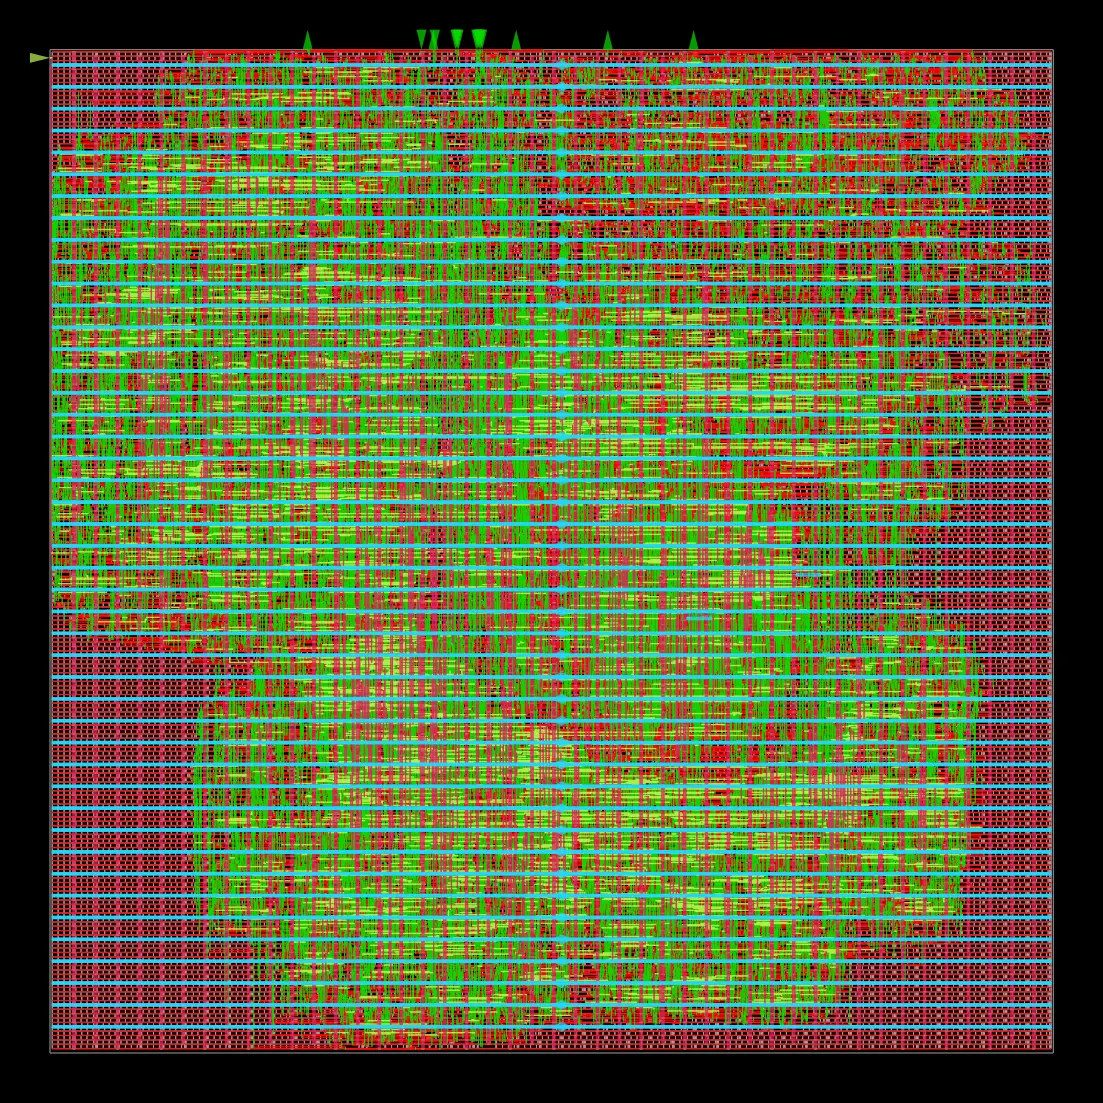

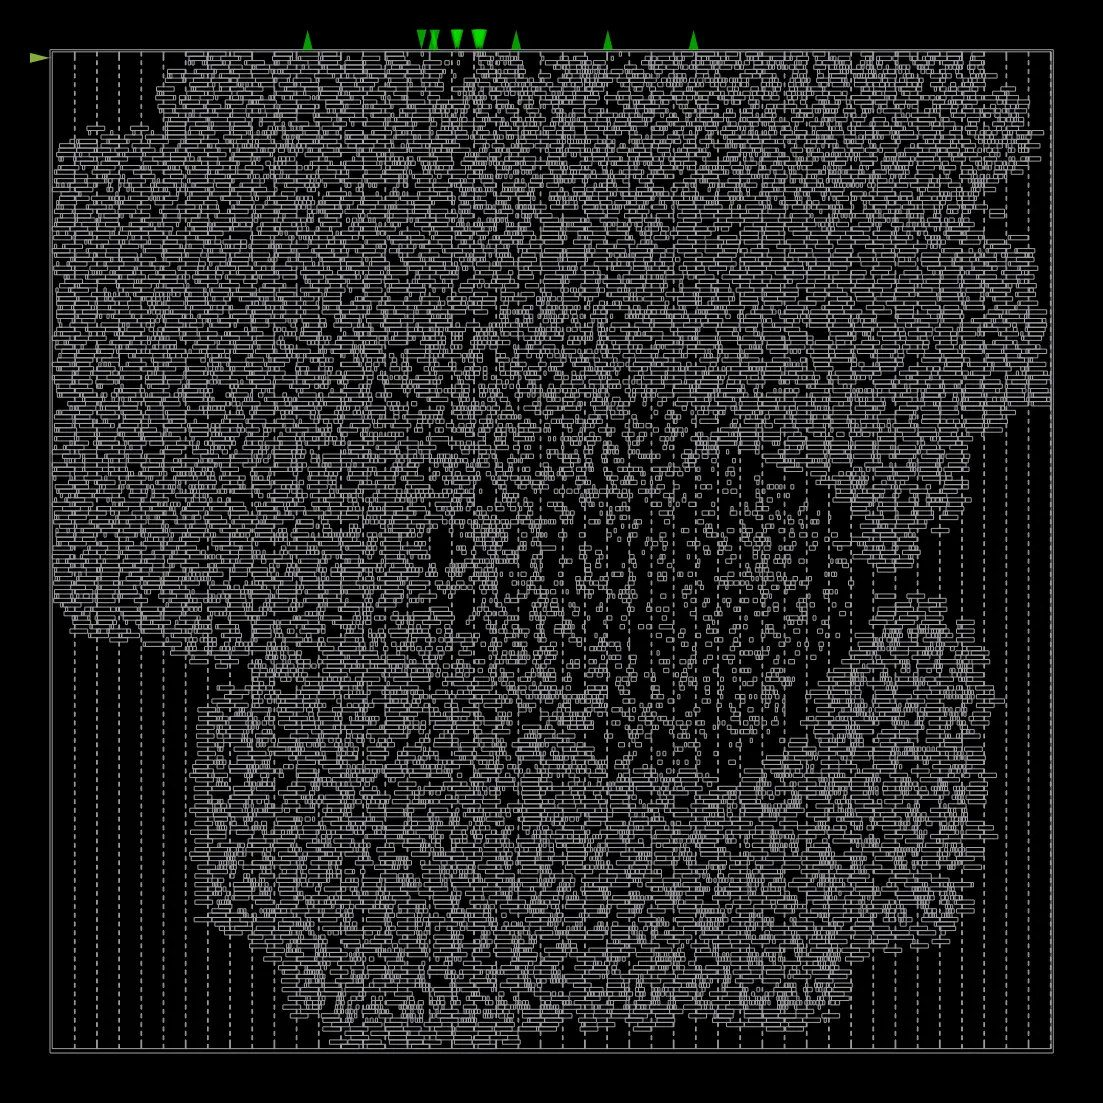

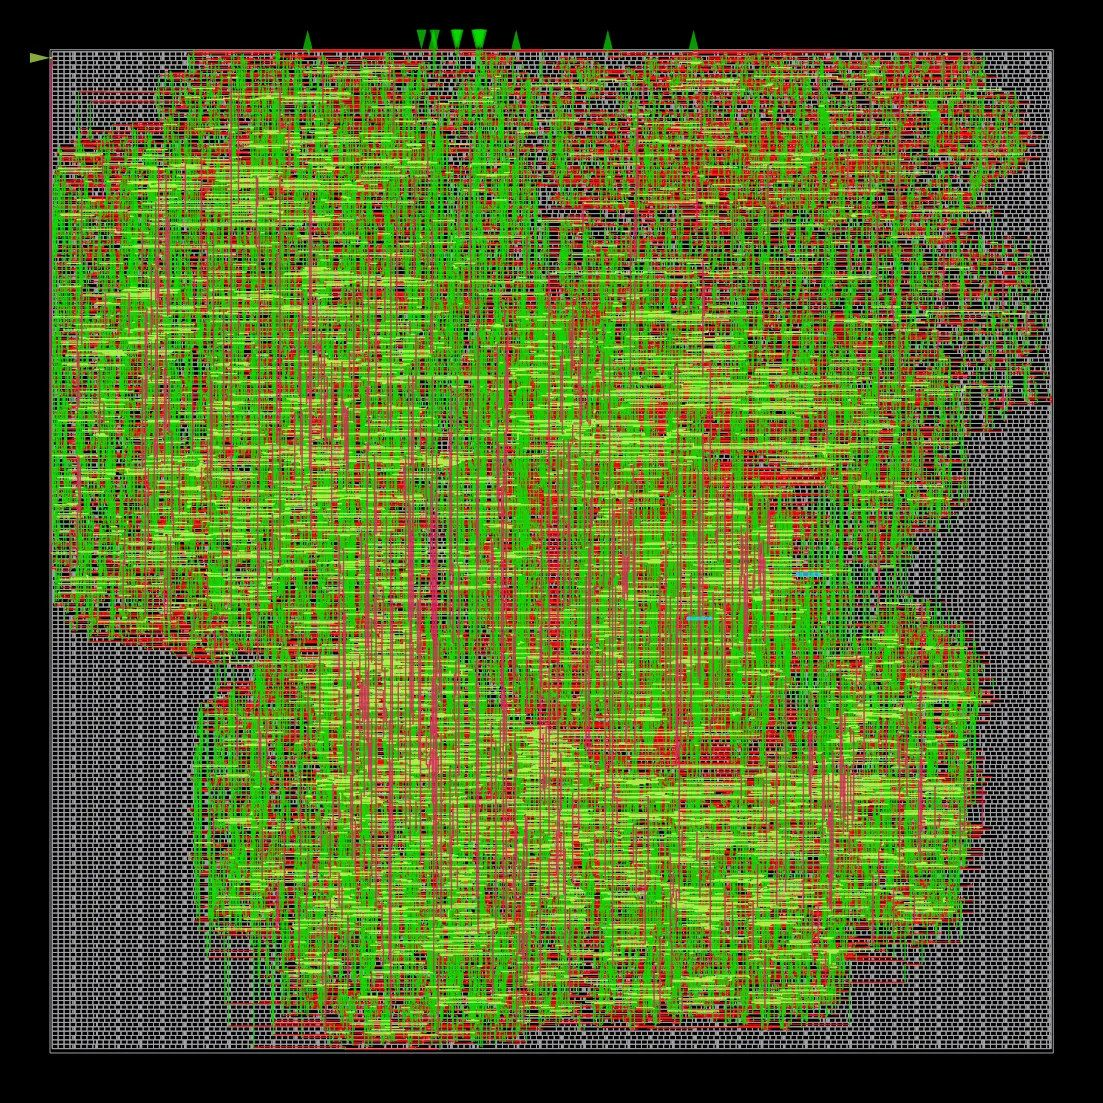

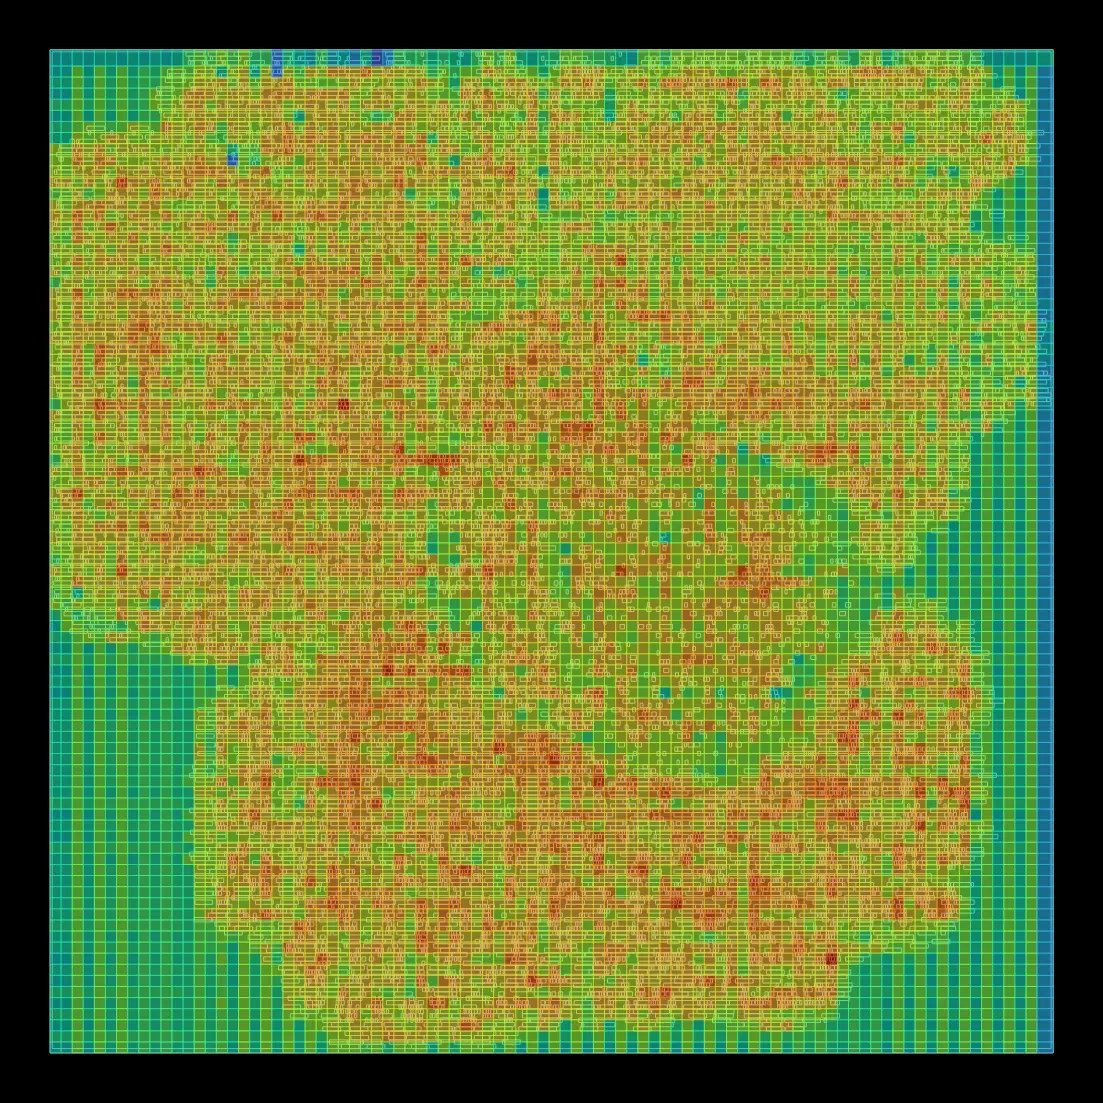

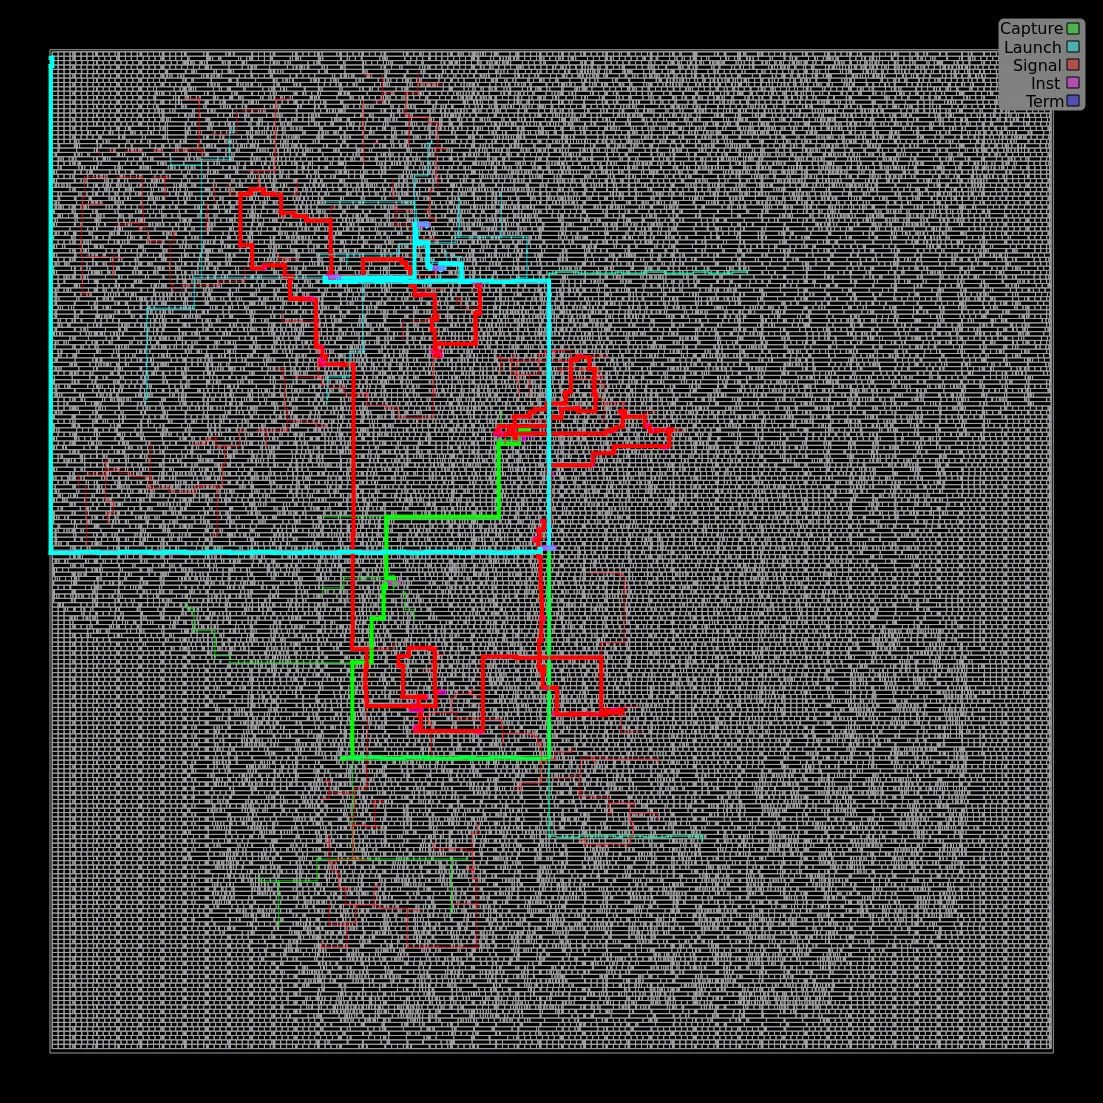

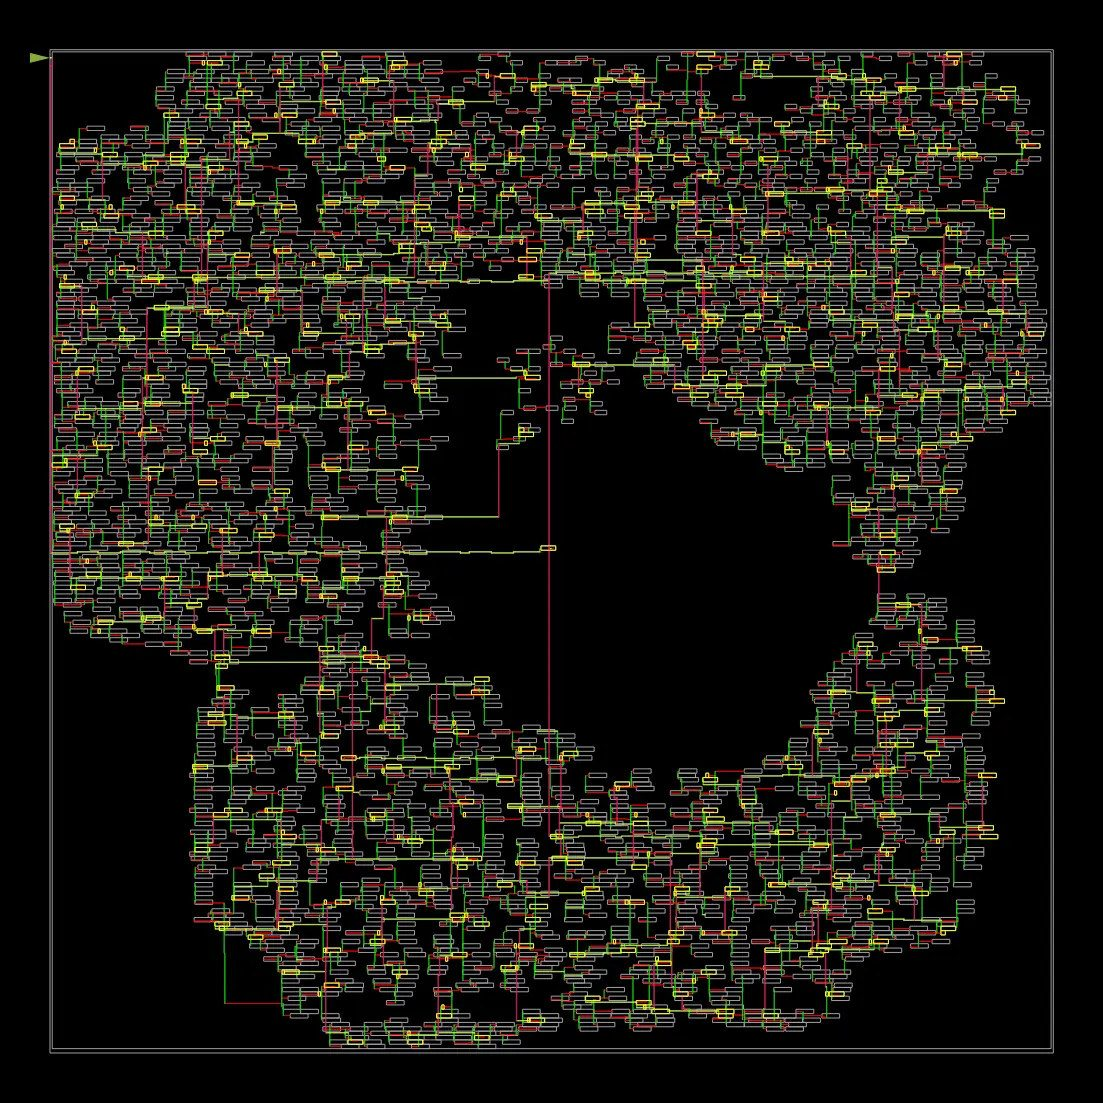

In [22]:
from PIL import Image as PILImage
from IPython.display import display, Image

reports = "/content/OpenROAD-flow-scripts/flow/reports/sky130hd/js_soc/base"

for name in ["final_all", "final_placement", "final_routing",
             "final_congestion", "final_worst_path", "final_clocks"]:
    out = f"/content/{name}.jpg"
    PILImage.open(f"{reports}/{name}.webp").convert("RGB").save(out, quality=88)
    display(Image(filename=out, width=640))

### 7.8 Physical-design report

In [23]:
from IPython.display import display, Markdown
from pathlib import Path
import xml.etree.ElementTree as ET
from datetime import datetime

gds = Path(
    "/content/OpenROAD-flow-scripts/flow/results/"
    "sky130hd/js_soc/base/6_final.gds"
)
drc_report = Path("/content/JS-SoC-final-drc.lyrdb")

assert gds.exists(), "Final GDS not found"
assert drc_report.exists(), "KLayout DRC report not found"

root = ET.parse(drc_report).getroot()
markers = root.findall(".//items/item")
gds_size = gds.stat().st_size / 1e6

report = f"""
# JS-SoC ASIC Physical Design Verification Report

**Platform:** Sky130HD
**Top module:** `top`
**Clock target:** 35 MHz
**Clock period:** 28.5714 ns
**Final layout:** `6_final.gds`

---

## DRC Verification Result

# ✅ {len(markers)} DRC Markers

The final GDS was checked using the Sky130HD KLayout DRC deck.

| Verification item | Result |
|---|---|
| KLayout execution | Successful |
| DRC report generated | Yes |
| DRC markers reported | **{len(markers)}** |
| Final GDS available | Yes |
| Final GDS size | {gds_size:.2f} MB |
| BEOL checks | Enabled |
| Off-grid checks | Enabled |
| FEOL checks | Disabled |

## Timing Information

| Parameter | Value |
|---|---:|
| Target frequency | 35 MHz |
| Clock period | 28.5714 ns |
| Global-route critical-path delay | 16.9348 ns |
| Global-route estimated slack | 12.4542 ns |

*Timing figures above are global-route estimates, not final signoff timing results.*

## Conclusion

The final GDS for the 35 MHz target produced **{len(markers)} DRC markers**
under the enabled Sky130HD BEOL and off-grid checks.

This result does not establish complete foundry signoff because FEOL checks
were disabled. Additional signoff verification may be required.

---
*Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}*
"""

display(Markdown(report))


# JS-SoC ASIC Physical Design Verification Report

**Platform:** Sky130HD  
**Top module:** `top`  
**Clock target:** 35 MHz  
**Clock period:** 28.5714 ns  
**Final layout:** `6_final.gds`

---

## DRC Verification Result

# ✅ 0 DRC Markers

The final GDS was checked using the Sky130HD KLayout DRC deck.

| Verification item | Result |
|---|---|
| KLayout execution | Successful |
| DRC report generated | Yes |
| DRC markers reported | **0** |
| Final GDS available | Yes |
| Final GDS size | 20.55 MB |
| BEOL checks | Enabled |
| Off-grid checks | Enabled |
| FEOL checks | Disabled |

## Timing Information

| Parameter | Value |
|---|---:|
| Target frequency | 35 MHz |
| Clock period | 28.5714 ns |
| Global-route critical-path delay | 16.9348 ns |
| Global-route estimated slack | 12.4542 ns |

*Timing figures above are global-route estimates, not final signoff timing results.*

## Conclusion

The final GDS for the 35 MHz target produced **0 DRC markers**
under the enabled Sky130HD BEOL and off-grid checks.

This result does not establish complete foundry signoff because FEOL checks
were disabled. Additional signoff verification may be required.

---
*Generated: 2026-10-30 13:18:38*


### 7.9 Sky130HD implementation summary

All values below are taken from the flow log and reports above.

| Metric | Value |
|---|---|
| Die / core | 624.21 × 624.21 µm / 385,405 µm² core area |
| Synthesized netlist | 14,222 instances, 154,857 µm² cell area |
| Final standard-cell area | 173,530 µm² (45 % utilization) |
| Sequential / combinational cells | 3,152 / 9,829 (+ 452 clock buffers, 527 timing-repair buffers) |
| Clock | 35 MHz (28.5714 ns) |
| Setup / hold after CTS and routing | No violations reported by `repair_timing` |
| Critical path (global-route estimate) | 16.93 ns delay, **+12.45 ns slack** |
| Total power (finish stage) | 9.54 mW at 1.8 V, worst-case IR drop 68 µV |
| Detailed-route DRC | **0** |
| KLayout DRC markers (BEOL + off-grid deck) | **0** |
| Final GDS | `6_final.gds`, 20.55 MB |

## 8. Results summary

| | Sky130HD |
|---|---|
| Flow | Yosys · OpenROAD (ORFS) · KLayout |
| Target clock | 35 MHz |
| Die size | 624 × 624 µm |
| Timing | No setup/hold violations |
| DRC | 0 (router) / 0 (KLayout) |
| Output | `6_final.gds` |

Functionally, the RTL passes the self-checking Icarus testbench (22 instructions, all register checks pass) and was cross-checked block by block in Vivado.

## 9. Reproducibility

```text
JS-SoC-Code-a-Chip/
├── rtl/                     # SoC_V3 SystemVerilog RTL (source of truth)
├── tb/top_tb.sv             # self-checking system testbench
├── programs/bootloader_demo.hex
├── scripts/run_sim.sh       # Icarus compile + run
├── docs/                    # architecture diagrams
├── results/
│   ├── simulation_log.txt   # Icarus console output
│   ├── bootloader_writing.png, execution.png
│   ├── build/js_soc.vcd     # waveform
│   ├── vivado/              # Vivado waveforms and APB FSM
│   └── openroad/            # Sky130HD layout views
└── notebook/JS_SoC_Code_a_Chip.ipynb
```

### Recommended tool versions

| Tool | Version used | Used in |
|---|---|---|
| Python / Jupyter | Python 3.10 or newer | Whole notebook |
| Icarus Verilog | 12.0 | Section 5 |
| AMD Vivado | 2024.1.2 | Section 6 (cross-verification only, not required to reproduce) |
| OpenROAD-flow-scripts (OpenROAD) | `26Q4-1310-g98c6045c72`, built from source | Section 7 |
| Yosys | 0.68+ (git `a5af9d690`) | Section 7 |
| KLayout | 0.30.12 | Section 7 |
| SkyWater PDK | `sky130hd` platform bundled with ORFS | Section 7 |
| Google Colab runtime | Ubuntu 24.04.5 LTS, 2 vCPUs | Section 7 |

### Steps

1. **RTL simulation:** run `./scripts/run_sim.sh` from the submission root, or run Section 5. Expect `SIMULATION PASS`.
2. **Waveforms:** open `results/build/js_soc.vcd` in GTKWave.
3. **Sky130HD physical design:** run the Section 7 cells on Google Colab, top to bottom. The final layout is written to `flow/results/sky130hd/js_soc/base/6_final.gds`.

## 10. Conclusion

JS-SoC takes one RTL code base from a self-checking simulation all the way to a routed, DRC-clean layout:

- **Functionally verified:** the hardware bootloader loads a 22-instruction program byte by byte, the core executes it, and every register check passes. Vivado waveforms confirm the bootloader, UART, Timer, PWM and integrated-SoC behaviour.
- **Implemented with open-source tools:** Sky130HD at 35 MHz with no timing violations and zero DRC markers, fully reproducible on Colab.

### License

Released under the **Apache License 2.0**. See `LICENSE` in the submission root.

### References

1. RISC-V International, *RISC-V ISA specifications*. https://docs.riscv.org/
2. Arm, *AMBA APB Protocol Specification*. https://developer.arm.com/documentation/ihi0024/latest/
3. Icarus Verilog. https://steveicarus.github.io/iverilog/
4. The OpenROAD Project, *OpenROAD-flow-scripts*. https://github.com/The-OpenROAD-Project/OpenROAD-flow-scripts
5. SkyWater Technology / Google, *SKY130 open-source PDK*. https://github.com/google/skywater-pdk
6. KLayout. https://www.klayout.de/
7. IEEE SSCS OSE Code-a-Chip. https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io
8. JS-SoC source repository. https://github.com/S-Steven-Joshua/JS-SoC

This notebook was written specifically for the JS-SoC design. No external notebook was reused as its basis.